In [3]:
!pip install -q kagglehub

In [4]:
import kagglehub

path = kagglehub.dataset_download("gti-upm/leapgestrecog")

print("Downloaded to:", path)

Using Colab cache for faster access to the 'leapgestrecog' dataset.
Downloaded to: /kaggle/input/leapgestrecog


In [5]:
import kagglehub

path = kagglehub.dataset_download("gti-upm/leapgestrecog")

print("Downloaded to:", path)

Using Colab cache for faster access to the 'leapgestrecog' dataset.
Downloaded to: /kaggle/input/leapgestrecog


In [6]:
import os

print(os.listdir(path))

['leapGestRecog', 'leapgestrecog']


In [7]:
import os

for folder in os.listdir(path):
    folder_path = os.path.join(path, folder)
    print(f"\n{folder}:")
    print(os.listdir(folder_path)[:15])


leapGestRecog:
['07', '05', '06', '02', '04', '00', '08', '09', '03', '01']

leapgestrecog:
['leapGestRecog']


In [8]:
import os

dataset_path = os.path.join(path, "leapGestRecog")

print(os.listdir(dataset_path))

['07', '05', '06', '02', '04', '00', '08', '09', '03', '01']


In [9]:
import os

folder_00 = os.path.join(dataset_path, "00")

print(os.listdir(folder_00))


['02_l', '04_fist_moved', '09_c', '10_down', '06_index', '08_palm_moved', '07_ok', '05_thumb', '01_palm', '03_fist']


In [10]:
gesture_path = os.path.join(folder_00, "01_palm")

print(os.listdir(gesture_path)[:10])

['frame_00_01_0025.png', 'frame_00_01_0045.png', 'frame_00_01_0070.png', 'frame_00_01_0125.png', 'frame_00_01_0086.png', 'frame_00_01_0140.png', 'frame_00_01_0004.png', 'frame_00_01_0156.png', 'frame_00_01_0067.png', 'frame_00_01_0076.png']


In [11]:
X = []
y = []

print("X and y are ready!")

X and y are ready!


In [12]:
subjects = os.listdir(dataset_path)

print(subjects)

['07', '05', '06', '02', '04', '00', '08', '09', '03', '01']


In [13]:
subject = "00"

subject_path = os.path.join(dataset_path, subject)

print(subject_path)

/kaggle/input/leapgestrecog/leapGestRecog/00


In [14]:
gesture_path = os.path.join(subject_path, "01_palm")

print(gesture_path)

/kaggle/input/leapgestrecog/leapGestRecog/00/01_palm


In [15]:
image_name = os.listdir(gesture_path)[0]

print(image_name)

frame_00_01_0025.png


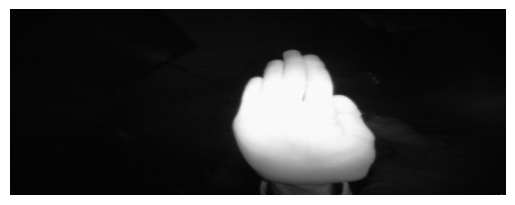

In [16]:
from PIL import Image
import matplotlib.pyplot as plt

image_path = os.path.join(gesture_path, image_name)

image = Image.open(image_path)

plt.imshow(image, cmap="gray")
plt.axis("off")
plt.show()

In [17]:
image_resized = image.resize((64, 64))

print("Original size:", image.size)
print("New size:", image_resized.size)

Original size: (640, 240)
New size: (64, 64)


In [20]:
import numpy as np

# Convert image to 64x64 NumPy array and normalize pixels
image_array = np.array(image_resized) / 255.0

print("Shape:", image_array.shape)
print("Pixel range:", image_array.min(), "to", image_array.max())

Shape: (64, 64)
Pixel range: 0.0196078431372549 to 1.0


In [21]:
X = []
y = []

gesture_folders = [
    "01_palm", "02_l", "03_fist", "04_fist_moved", "05_thumb",
    "06_index", "07_ok", "08_palm_moved", "09_c", "10_down"
]

for subject in subjects:
    subject_path = os.path.join(dataset_path, subject)

    for label, gesture in enumerate(gesture_folders):
        gesture_path = os.path.join(subject_path, gesture)

        for image_name in os.listdir(gesture_path):
            image_path = os.path.join(gesture_path, image_name)

            try:
                img = Image.open(image_path).convert("L")
                img = img.resize((64, 64))

                X.append(np.array(img) / 255.0)
                y.append(label)
            except:
                pass

X = np.array(X)
y = np.array(y)

print("Images:", X.shape)
print("Labels:", y.shape)

Images: (20000, 64, 64)
Labels: (20000,)


In [22]:
X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (20000, 64, 64)
y shape: (20000,)


In [23]:
X = X.reshape(-1, 64, 64, 1)

print("X shape:", X.shape)

X shape: (20000, 64, 64, 1)


In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (16000, 64, 64, 1)
Testing: (4000, 64, 64, 1)


In [25]:
from tensorflow.keras import models, layers

model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation="relu", input_shape=(64, 64, 1)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(10, activation="softmax")
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 683,914 (2.61 MB)

 Trainable params: 683,914 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

In [26]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [27]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 90s 221ms/step - accuracy: 0.8503 - loss: 0.4482 - val_accuracy: 0.9966 - val_loss: 0.0124
Epoch 2/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 88s 221ms/step - accuracy: 0.9891 - loss: 0.0393 - val_accuracy: 0.9991 - val_loss: 0.0026
Epoch 3/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 88s 220ms/step - accuracy: 0.9926 - loss: 0.0249 - val_accuracy: 0.9987 - val_loss: 0.0078
Epoch 4/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 141s 217ms/step - accuracy: 0.9925 - loss: 0.0232 - val_accuracy: 0.9991 - val_loss: 0.0020
Epoch 5/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 146s 227ms/step - accuracy: 0.9973 - loss: 0.0095 - val_accuracy: 1.0000 - val_loss: 1.1647e-04
Epoch 6/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 138s 217ms/step - accuracy: 0.9948 - loss: 0.0180 - val_accuracy: 0.9997 - val_loss: 8.7960e-04
Epoch 7/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 89s 222ms/step - accuracy: 0.9948 - loss: 0.0165 - val_accuracy: 0.9987 - val_loss: 0.0040
Epoch 8/10
400/400 ━━━━━━━━━━━━━━━━━━━━ 142s 222ms/step - accuracy: 0.99

In [28]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 52ms/step - accuracy: 0.9998 - loss: 0.0015
Test Accuracy: 0.999750018119812
Test Loss: 0.0014781837817281485


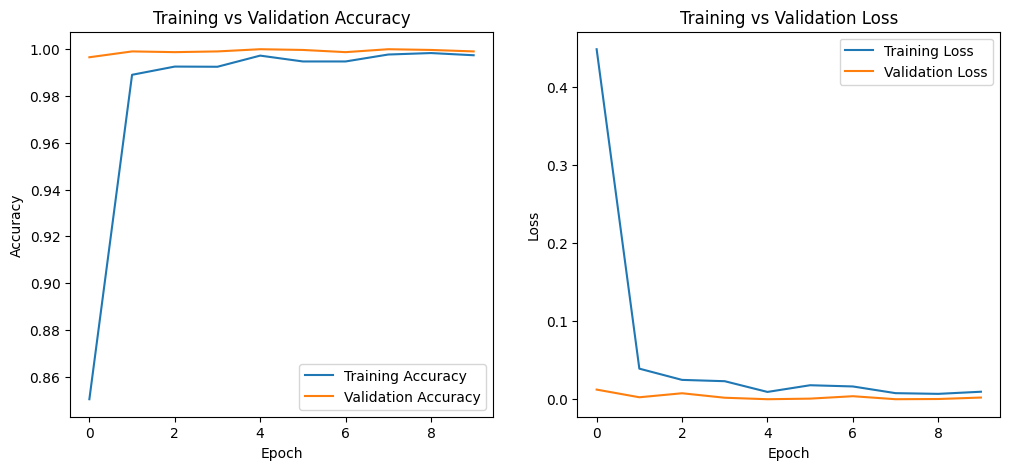

In [29]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 64ms/step


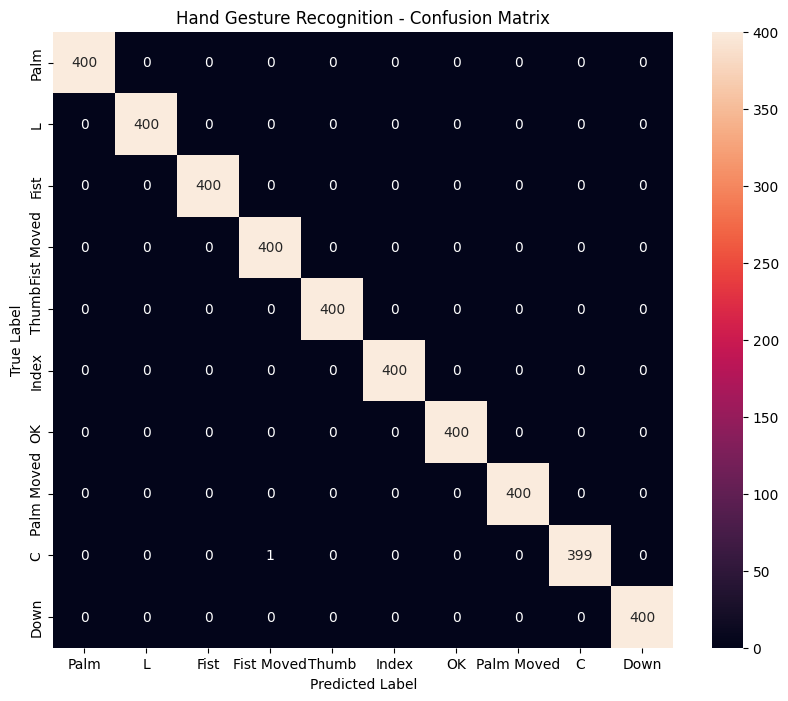

In [30]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

class_names = [
    "Palm", "L", "Fist", "Fist Moved", "Thumb",
    "Index", "OK", "Palm Moved", "C", "Down"
]

# Get predictions
predictions = model.predict(X_test)
predicted_labels = np.argmax(predictions, axis=1)

# Create confusion matrix
cm = confusion_matrix(y_test, predicted_labels)

# Display it
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Hand Gesture Recognition - Confusion Matrix")
plt.show()

In [31]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    predicted_labels,
    target_names=class_names
))

              precision    recall  f1-score   support

        Palm       1.00      1.00      1.00       400
           L       1.00      1.00      1.00       400
        Fist       1.00      1.00      1.00       400
  Fist Moved       1.00      1.00      1.00       400
       Thumb       1.00      1.00      1.00       400
       Index       1.00      1.00      1.00       400
          OK       1.00      1.00      1.00       400
  Palm Moved       1.00      1.00      1.00       400
           C       1.00      1.00      1.00       400
        Down       1.00      1.00      1.00       400

    accuracy                           1.00      4000
   macro avg       1.00      1.00      1.00      4000
weighted avg       1.00      1.00      1.00      4000



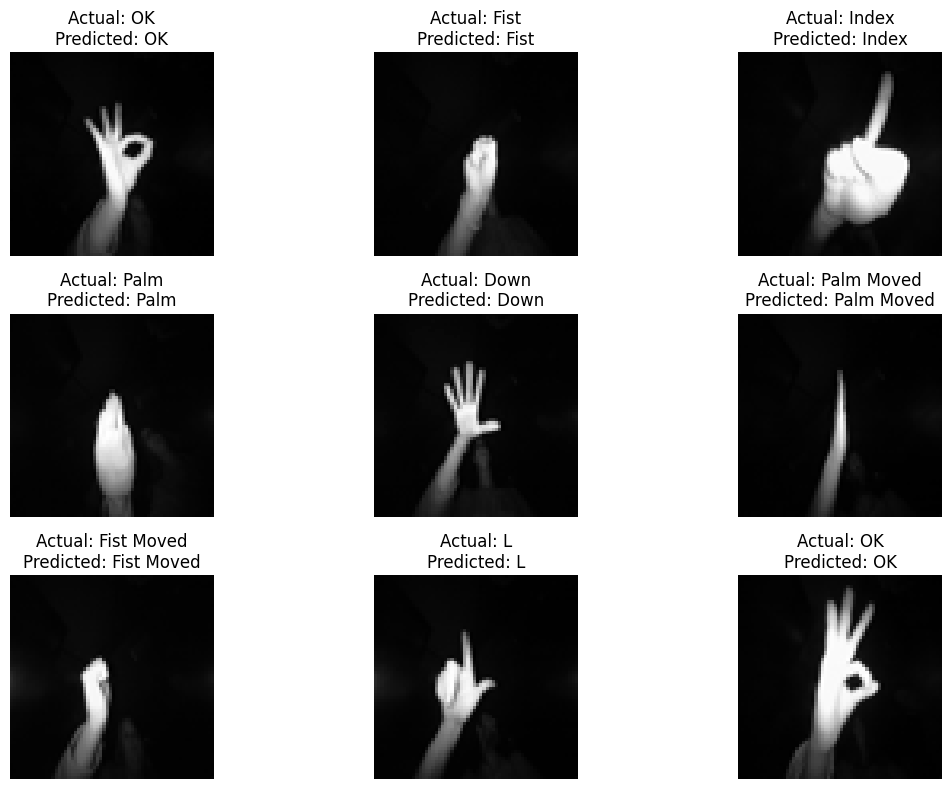

In [33]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)

    plt.imshow(X_test[i].reshape(64, 64), cmap="gray")

    actual = class_names[y_test[i]]
    predicted = class_names[predicted_labels[i]]

    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Conclusion

The Hand Gesture Recognition model was successfully developed using a **Convolutional Neural Network (CNN)** and the **LeapGestRecog dataset**. The model was trained on 20,000 grayscale hand gesture images across 10 different gesture classes. After preprocessing and training for 10 epochs, the model achieved a **99.975% test accuracy**, correctly classifying 3,999 out of 4,000 test images. This project helped demonstrate how CNNs can effectively learn visual patterns and classify different hand gestures from images.
